In [5]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import summarize_runs as sr

import glob
from matplotlib.patches import Patch


In [6]:
# Path to the CSV file (relative to scripts directory)
csv_path1 = '../simulation_results/yinyang/simulation_wandb_export_sfc.csv'
csv_path2 = '../simulation_results/yinyang/simulation_wandb_export_surrogategrad_MSE.csv'
csv_path3 = '../simulation_results/yinyang/simulation_wandb_export_backprop_crossentropy.csv'

df1 = pd.read_csv(csv_path1, sep=';')
df2 = pd.read_csv(csv_path2, sep=';')
df2.rename(columns={'test accuracy (Max)': 'test accuracy N/A'}, inplace=True)
df2.rename(columns={'eval accuracy': 'test accuracy (Max)'}, inplace=True)
df3 = pd.read_csv(csv_path3, sep=';')
# Merge the dataframes together
df = pd.concat([df1, df2, df3], ignore_index=True) # Filter and group the simulation data

group_order = ['locally-learnt', 'frozen-hidden', 'fixed-feedback', 'surrogate gradient', 'backprop']
df = df[df['note'].isin(group_order)].copy()
metrics = ['test accuracy (Max)', 'test target error']
grouped_mean = df.groupby('note')[metrics].mean().reindex(group_order)
grouped_std = df.groupby('note')[metrics].std().reindex(group_order)

print(grouped_mean)


                    test accuracy (Max)  test target error
note                                                      
locally-learnt                 0.746373          11.969736
frozen-hidden                  0.727209          11.889803
fixed-feedback                 0.733538          14.697135
surrogate gradient             0.826004                NaN
backprop                       0.830134                NaN


In [7]:

# 1. Load Dynapse runs using summarize_runs
dynapse_frozen_paths = glob.glob('../dynapse_results/mnist1d/frozen/*')
dynapse_full_paths = glob.glob('../dynapse_results/mnist1d/full/*')

dynapse_frozen_runs = sr.load_runs(dynapse_frozen_paths)
dynapse_full_runs = sr.load_runs(dynapse_full_paths)

# 2. Compute statistics for Dynapse
dynapse_frozen_stats = sr.compute_stats(dynapse_frozen_runs)
dynapse_full_stats = sr.compute_stats(dynapse_full_runs)

# 3. Extract the 'test' metrics for Dynapse 
eval_pt = 'test'
dynapse_acc_frozen = dynapse_frozen_stats['classification_accuracy'][eval_pt]
dynapse_acc_full = dynapse_full_stats['classification_accuracy'][eval_pt]
dynapse_err_frozen = dynapse_frozen_stats['target_error'][eval_pt]
dynapse_err_full = dynapse_full_stats['target_error'][eval_pt]

# Organize means and stds for plotting in the order: [Frozen Hidden, Locally Learnt, Fixed Feedback]
sim_acc_means = grouped_mean['test accuracy (Max)'].values
sim_acc_stds = grouped_std['test accuracy (Max)'].values/np.sqrt(len(grouped_std['test accuracy (Max)'].values))
sim_err_means = grouped_mean['test target error'].values
sim_err_stds = grouped_std['test target error'].values/np.sqrt(len(grouped_std['test accuracy (Max)'].values))

# Dynapse metrics (zeros for the missing 'fixed-feedback' condition)
dynapse_acc_means = [dynapse_acc_full['mean'], dynapse_acc_frozen['mean'], 0.0, 0.0, 0.0]
dynapse_acc_stds = [dynapse_acc_full['std'], dynapse_acc_frozen['std'], 0.0, 0.0, 0.0]

dynapse_err_means = [dynapse_err_full['mean'], dynapse_err_frozen['mean'], 0.0, 0.0, 0.0]
dynapse_err_stds = [dynapse_err_full['std'], dynapse_err_frozen['std'], 0.0, 0.0, 0.0]



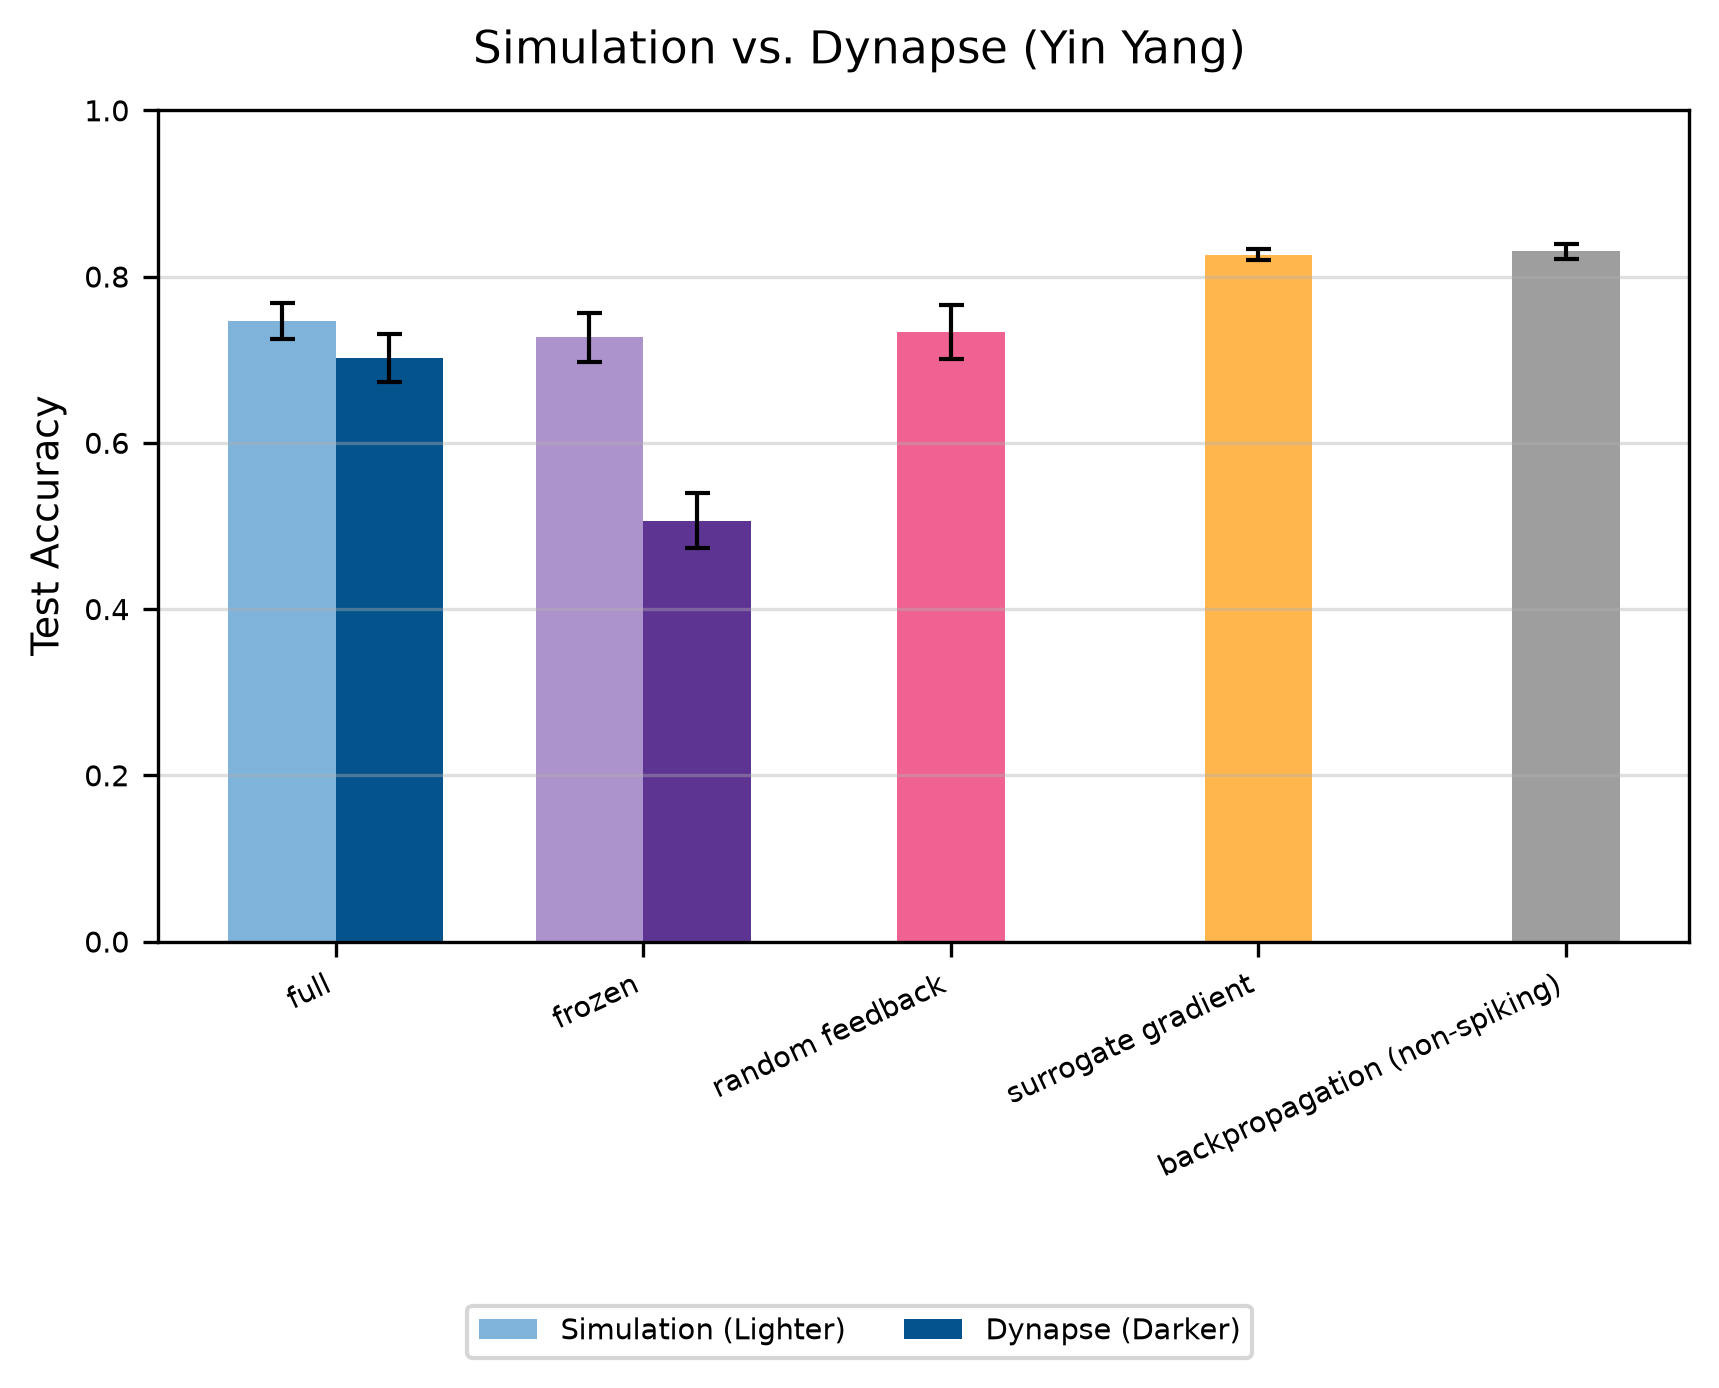

In [8]:
# 4. Set up the grouped bar plot
sr.latexify(width_fraction=0.95, base_font_size=9, height_ratio=0.7)
fig, axes = plt.subplots(1, 1, constrained_layout=True, squeeze=False)

x = np.arange(len(group_order))
width = 0.35  # Adjust width for two bars side-by-side

# Define distinct colors for the 3 conditions (Light for Sim, Dark for Dynapse)
sim_colors = [sr.COLOR_TRAIN_LIGHT, sr.COLOR_VAL_LIGHT, '#F06292', '#FFB74D', '#9E9E9E', '#81C784', ] # Light Blue, Light Purple, Light Orange
dynapse_colors = [sr.COLOR_TRAIN, sr.COLOR_VAL, '#C2185B', '#E65100', '#424242', '#388E3C', ]       # Dark Blue, Dark Purple, Dark Orange

# -- Panel 1: Test Accuracy --
ax = axes[0][0]
for i in range(len(x)):
    if dynapse_acc_means[i] > 0:
        ax.bar(x[i] - width/2, sim_acc_means[i], width, yerr=sim_acc_stds[i], capsize=3, color=sim_colors[i], error_kw={'elinewidth': 1})
        ax.bar(x[i] + width/2, dynapse_acc_means[i], width, yerr=dynapse_acc_stds[i], capsize=3, color=dynapse_colors[i], error_kw={'elinewidth': 1})
    else:
        ax.bar(x[i], sim_acc_means[i], width, yerr=sim_acc_stds[i], capsize=3, color=sim_colors[i], error_kw={'elinewidth': 1})

ax.set_xticks(x)
tick_labels = [note.replace('-', ' ').title() for note in group_order]
tick_labels = ['full', 'frozen', 'random feedback', 'surrogate gradient', 'backpropagation (non-spiking)']
ax.set_xticklabels(tick_labels, rotation=25, ha='right')
ax.set_ylabel('Test Accuracy')
ax.set_ylim(0.0, 1.0)
ax.grid(True, axis='y', alpha=0.4)

# -- Panel 2: Test Target Error --
# ax = axes[0][1]
    # for i in range(len(x)):
    #     if dynapse_acc_means[i] > 0:
    #         ax.bar(x[i] - width/2, sim_err_means[i], width, yerr=sim_err_stds[i], capsize=3, color=sim_colors[i], error_kw={'elinewidth': 1})
    #         ax.bar(x[i] + width/2, dynapse_err_means[i], width, yerr=dynapse_err_stds[i], capsize=3, color=dynapse_colors[i], error_kw={'elinewidth': 1})
    #     else:
    #         ax.bar(x[i], sim_err_means[i], width, yerr=sim_err_stds[i], capsize=3, color=sim_colors[i], error_kw={'elinewidth': 1})

# ax.set_xticks(x)
# ax.set_xticklabels(tick_labels, rotation=25, ha='right')
# ax.set_ylabel('Test Target Error [Hz]')
# ax.grid(True, axis='y', alpha=0.4)

# Create a custom legend explaining the shading
legend_elements = [
    Patch(facecolor=sim_colors[0], label='Simulation (Lighter)'),
    Patch(facecolor=dynapse_colors[0], label='Dynapse (Darker)')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.15))

fig.suptitle("Simulation vs. Dynapse (Yin Yang)")

# Optional save
save = False
if save:
    fig.savefig('sim_vs_dynapse_comparison.pdf', dpi=300, bbox_inches='tight')
    fig.savefig('sim_vs_dynapse_comparison.png', dpi=300, bbox_inches='tight')

plt.show()
